In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
text_col = next(
    (c for c in ["Text", "text", "Sentence", "sentence"] if c in df.columns),
    None
)

label_col = next(
    (c for c in ["Language", "language", "lang", "labels"] if c in df.columns),
    None
)

if text_col is None or label_col is None:
    raise ValueError("Check the column names displayed in Cell 2.")

df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

df.dropna(inplace=True)

df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[(df["text"] != "") & (df["language"] != "")]
df.drop_duplicates(subset=["text", "language"], inplace=True)

df = (
    df.groupby("language", group_keys=False)
    .apply(lambda g: g.sample(min(len(g), 1000), random_state=42))
    .reset_index(drop=True)
)

print("Preprocessing completed!")
print(df.head())
print("Total samples:", len(df))

Preprocessing completed!
                                                text language
0  في فبراير م أرسل الزعيم مصطفى النحاس احتجاجا إ...   Arabic
1  يبحث الناقد في المذاهب التقليدية عن قصدية الفن...   Arabic
2  بدأ مراد حياته كأحد مماليك علي بك الكبير وكان ...   Arabic
3  المنظومات التمثيلية analog systems يتم في هذه ...   Arabic
4  شاركت معقل قبائل بني هلال وباقي القبائل القيسي...   Arabic
Total samples: 17600


/tmp/ipykernel_922/2405291304.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 1000), random_state=42))


In [15]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["language"])

MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df["text"])

X = tokenizer.texts_to_sequences(df["text"])
X = pad_sequences(X, maxlen=MAX_LEN, padding="post", truncating="post")

print("Tokenization completed!")
print("Input shape:", X.shape)
print("Number of languages:", len(encoder.classes_))

Tokenization completed!
Input shape: (17600, 100)
Number of languages: 22


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 14080
Testing samples: 3520


In [17]:
model = Sequential([
    Embedding(MAX_WORDS, 64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(len(encoder.classes_), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.2979 - loss: 2.2636 - val_accuracy: 0.6463 - val_loss: 1.3282
Epoch 2/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - accuracy: 0.7251 - loss: 0.9506 - val_accuracy: 0.7692 - val_loss: 0.8449
Epoch 3/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 21s 58ms/step - accuracy: 0.8507 - loss: 0.5065 - val_accuracy: 0.8920 - val_loss: 0.3574
Epoch 4/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 13s 62ms/step - accuracy: 0.9080 - loss: 0.3078 - val_accuracy: 0.8935 - val_loss: 0.3459
Epoch 5/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.9302 - loss: 0.2070 - val_accuracy: 0.9126 - val_loss: 0.2843


In [19]:
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average="weighted", zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average="weighted", zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, average="weighted", zero_division=0
))

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
Accuracy: 0.9190340909090909
Precision: 0.9162579903038722
Recall: 0.9190340909090909
F1-score: 0.9074434752721776
              precision    recall  f1-score   support

      Arabic       0.95      1.00      0.97       160
     Chinese       0.46      0.90      0.61       160
       Dutch       0.99      0.99      0.99       160
     English       0.92      0.96      0.94       160
    Estonian       0.97      0.93      0.95       160
      French       0.94      0.97      0.95       160
       Hindi       1.00      0.97      0.99       160
  Indonesian       0.99      0.97      0.98       160
    Japanese       0.36      0.03      0.05       160
      Korean       0.96      0.99      0.97       160
       Latin       0.94      0.92      0.93       160
     Persian       1.00      0.99      1.00       160
   Portugese       0.96      0.98      0.97       160
      Pushto       0.98      0.95      0.97       160
    Romanian       0.98      0.9

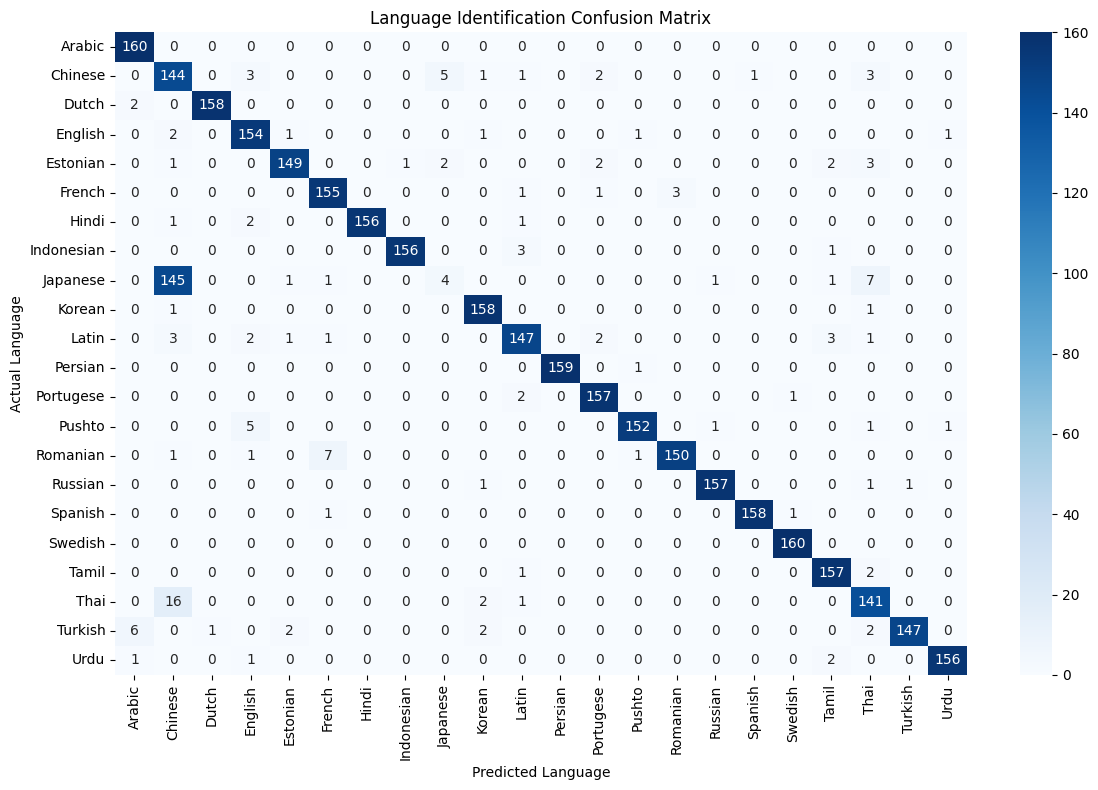

In [20]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("Language Identification Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [21]:
unseen_texts = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, como estas?",
    "Guten Morgen, wie geht es Ihnen?",
    "Ciao, come stai?"
]

sequences = tokenizer.texts_to_sequences(unseen_texts)

padded = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

probs = model.predict(padded)
predicted_ids = np.argmax(probs, axis=1)

for text, pred_id, prob in zip(unseen_texts, predicted_ids, probs):
    language = encoder.inverse_transform([pred_id])[0]
    print("\nText:", text)
    print("Predicted language:", language)
    print("Confidence:", round(float(prob[pred_id]) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step

Text: Hello, how are you?
Predicted language: Chinese
Confidence: 39.49 %

Text: Bonjour, comment allez-vous?
Predicted language: Chinese
Confidence: 43.94 %

Text: Hola, como estas?
Predicted language: Chinese
Confidence: 24.0 %

Text: Guten Morgen, wie geht es Ihnen?
Predicted language: Chinese
Confidence: 43.7 %

Text: Ciao, come stai?
Predicted language: Chinese
Confidence: 45.55 %
